<a href="https://colab.research.google.com/github/PixelPixe/Movie-Review-Sentiment-Analysis-using-Deep-Learning/blob/main/MovieReviewSentimentAnalysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
from tensorflow.keras.datasets import imdb
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense
from tensorflow.keras.preprocessing import sequence

In [ ]:
from google.colab import files
files.upload()

Saving kaggle (1).json to kaggle (1).json


{'kaggle (1).json': b'{"username":"aditiganguli","key":"0377f5f7d5640fb489be0ce61bb9af07"}'}

In [ ]:
!mkdir -p ~/.kaggle
!cp "kaggle (1).json" ~/.kaggle/kaggle.json
!chmod 600 ~/.kaggle/kaggle.json

In [ ]:
!ls ~/.kaggle

kaggle.json


In [ ]:
!kaggle datasets download -d lakshmi25npathi/imdb-dataset-of-50k-movie-reviews

Dataset URL: https://www.kaggle.com/datasets/lakshmi25npathi/imdb-dataset-of-50k-movie-reviews
License(s): other
  0% 0.00/25.7M [00:00<?, ?B/s]
100% 25.7M/25.7M [00:00<00:00, 887MB/s]


In [ ]:
!unzip imdb-dataset-of-50k-movie-reviews.zip

Archive:  imdb-dataset-of-50k-movie-reviews.zip
  inflating: IMDB Dataset.csv        


In [ ]:
import pandas as pd

data = pd.read_csv("IMDB Dataset.csv")
data.head()

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [ ]:
print(data.shape)
print(data['sentiment'].value_counts())

(50000, 2)
sentiment
positive    25000
negative    25000
Name: count, dtype: int64


In [ ]:
import pandas as pd

data = pd.read_csv("IMDB Dataset.csv", encoding='utf-8')
data.head()


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [ ]:
from sklearn.model_selection import train_test_split


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(data['review'], data['sentiment'], test_size=0.2, random_state=42)


In [ ]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences


In [ ]:
vocab_size = 10000
max_length = 200

tokenizer = Tokenizer(num_words=vocab_size, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train)

X_train_seq = tokenizer.texts_to_sequences(X_train)
X_test_seq = tokenizer.texts_to_sequences(X_test)

X_train_pad = pad_sequences(X_train_seq, maxlen=max_length, padding='post', truncating='post')
X_test_pad = pad_sequences(X_test_seq, maxlen=max_length, padding='post', truncating='post')


In [ ]:
X_train_padded = pad_sequences(X_train_seq, maxlen=max_length, padding='post', truncating='post')
X_test_padded = pad_sequences(X_test_seq, maxlen=max_length, padding='post', truncating='post')

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout


In [ ]:
model = Sequential([
    Embedding(vocab_size, 128),
    LSTM(64, return_sequences=False),
    Dropout(0.3),
    Dense(32, activation='relu'),
    Dropout(0.2),
    Dense(1, activation='sigmoid')
])

model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
y_train_encoded = le.fit_transform(y_train)
y_test_encoded = le.transform(y_test)


In [ ]:
history = model.fit(
    X_train_pad, y_train_encoded,
    epochs=3,
    validation_data=(X_test_pad, y_test_encoded),
    batch_size=128,
    verbose=1
)


Epoch 1/3
313/313 ━━━━━━━━━━━━━━━━━━━━ 123s 385ms/step - accuracy: 0.5303 - loss: 0.6905 - val_accuracy: 0.5715 - val_loss: 0.6713
Epoch 2/3
313/313 ━━━━━━━━━━━━━━━━━━━━ 119s 379ms/step - accuracy: 0.6015 - loss: 0.6559 - val_accuracy: 0.5322 - val_loss: 0.6872
Epoch 3/3
313/313 ━━━━━━━━━━━━━━━━━━━━ 141s 377ms/step - accuracy: 0.5843 - loss: 0.6550 - val_accuracy: 0.7304 - val_loss: 0.5530


In [ ]:
loss, accuracy = model.evaluate(X_test_pad, y_test_encoded)
print(f"Test Accuracy: {accuracy*100:.2f}%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 11s 36ms/step - accuracy: 0.7253 - loss: 0.5602
Test Accuracy: 73.04%


In [ ]:
import numpy as np

sample = ["The movie was absolutely wonderful! I loved it."]
seq = tokenizer.texts_to_sequences(sample)
pad = pad_sequences(seq, maxlen=max_length, padding='post', truncating='post')
pred = model.predict(pad)
print("Positive" if pred[0][0] > 0.5 else "Negative")


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
Negative


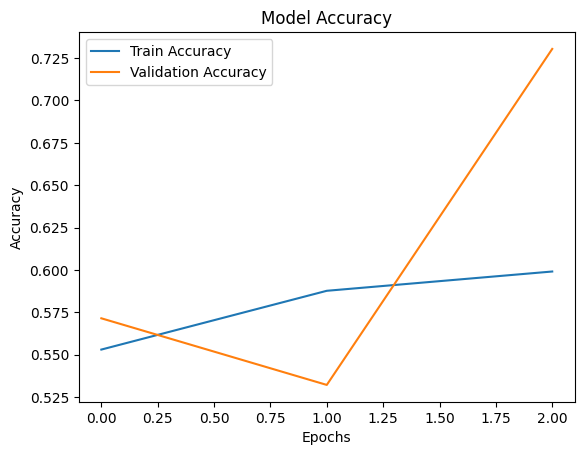

In [ ]:
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.legend()
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('Model Accuracy')
plt.show()


In [ ]:
model = Sequential([
    Embedding(vocab_size, 128, input_length=max_length),
    LSTM(128, return_sequences=True),
    Dropout(0.4),
    LSTM(64),
    Dense(32, activation='relu'),
    Dropout(0.3),
    Dense(1, activation='sigmoid')
])


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [ ]:
model.compile(
    loss='binary_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

In [ ]:
history = model.fit(
    X_train_pad, y_train_encoded,
    epochs=6,
    validation_data=(X_test_pad, y_test_encoded),
    batch_size=128,
    verbose=1
)


Epoch 1/6
313/313 ━━━━━━━━━━━━━━━━━━━━ 355s 1s/step - accuracy: 0.5274 - loss: 0.6884 - val_accuracy: 0.5039 - val_loss: 0.6890
Epoch 2/6
313/313 ━━━━━━━━━━━━━━━━━━━━ 346s 1s/step - accuracy: 0.5075 - loss: 0.6901 - val_accuracy: 0.5045 - val_loss: 0.6883
Epoch 3/6
313/313 ━━━━━━━━━━━━━━━━━━━━ 345s 1s/step - accuracy: 0.5017 - loss: 0.6894 - val_accuracy: 0.5104 - val_loss: 0.6848
Epoch 4/6
313/313 ━━━━━━━━━━━━━━━━━━━━ 360s 1s/step - accuracy: 0.5294 - loss: 0.6839 - val_accuracy: 0.6294 - val_loss: 0.6427
Epoch 5/6
313/313 ━━━━━━━━━━━━━━━━━━━━ 345s 1s/step - accuracy: 0.6427 - loss: 0.6415 - val_accuracy: 0.6212 - val_loss: 0.6493
Epoch 6/6
313/313 ━━━━━━━━━━━━━━━━━━━━ 344s 1s/step - accuracy: 0.6499 - loss: 0.6323 - val_accuracy: 0.6768 - val_loss: 0.6088


In [ ]:
loss, accuracy = model.evaluate(X_test_pad, y_test_encoded)
print(f"Test Accuracy: {accuracy*100:.2f}%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 39s 125ms/step - accuracy: 0.6782 - loss: 0.6091
Test Accuracy: 67.68%


In [ ]:
import numpy as np

sample = ["The movie was absolutely wonderful! I loved it."]
seq = tokenizer.texts_to_sequences(sample)
pad = pad_sequences(seq, maxlen=max_length, padding='post', truncating='post')
pred = model.predict(pad)
print("Positive" if pred[0][0] > 0.5 else "Negative")


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 341ms/step
Positive


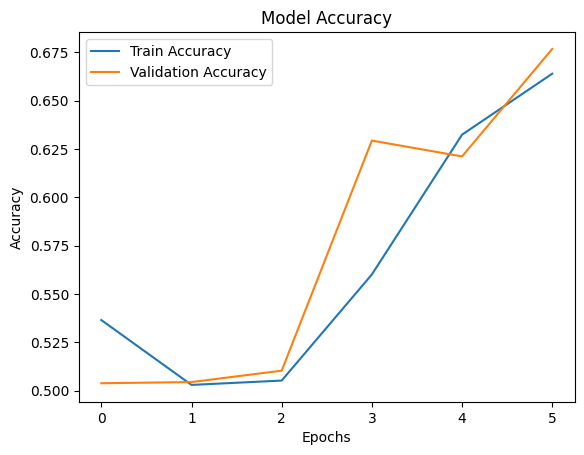

In [ ]:
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.legend()
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('Model Accuracy')
plt.show()


In [ ]:
from sklearn.metrics import classification_report

y_pred = (model.predict(X_test_pad) > 0.5).astype(int)
print(classification_report(y_test_encoded, y_pred, target_names=['Negative', 'Positive']))


313/313 ━━━━━━━━━━━━━━━━━━━━ 44s 138ms/step
              precision    recall  f1-score   support

    Negative       0.66      0.73      0.69      4961
    Positive       0.70      0.63      0.66      5039

    accuracy                           0.68     10000
   macro avg       0.68      0.68      0.68     10000
weighted avg       0.68      0.68      0.68     10000



313/313 ━━━━━━━━━━━━━━━━━━━━ 42s 134ms/step


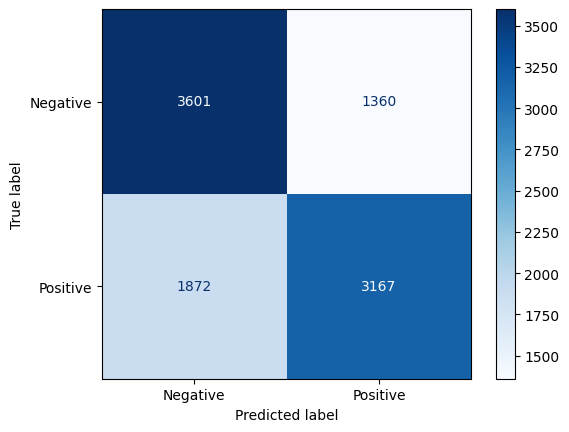

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Predict on test data
y_pred = (model.predict(X_test_pad) > 0.5).astype("int32")

# Create confusion matrix
cm = confusion_matrix(y_test_encoded, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Negative", "Positive"])
disp.plot(cmap="Blues")
